# 🔍 **EDA Кейс: Анализ оттока клиентов (Telco Customer Churn)**

**Датасет:** Telco Customer Churn (Kaggle)  
**Исследовательский вопрос:** «Какие клиенты склонны уходить и какие факторы связаны с оттоком клиентов?»  

---

# **Часть 1. Бизнес-контекст, цели проекта и задачи исследования**

## **1.1 Бизнес-контекст и верхнеуровневые цели**

### «Какие клиенты склонны уходить и какие факторы связаны с оттоком клиентов?»

**Бизнес-кейс:**  
Телекоммуникационная компания стремится снизить отток абонентов и сохранить клиентскую базу. Уход клиентов приводит к потере регулярной выручки и увеличивает затраты компании на привлечение новых абонентов. Поэтому компании важно своевременно выявлять клиентов с повышенным риском ухода и понимать, какие характеристики связаны с оттоком.  
**Бизнес-задача:**  
Исследовать факторы оттока абонентов на основе данных об их характеристиках, подключённых услугах, условиях контрактов и платежах. Подготовить аналитическую основу для построения модели машинного обучения, прогнозирующей вероятность ухода абонента.  
**Цель проекта:**  
Разработать модель машинного обучения для прогнозирования оттока абонентов телекоммуникационной компании и выявить ключевые факторы, связанные с уходом клиентов.
Полученные результаты помогут компании своевременно выявлять клиентов с высоким риском ухода и разрабатывать мероприятия по их удержанию.

### Датасет Telco Customer Churn
Датасет содержит информацию об абонентах телекоммуникационной компании, их демографических характеристиках, подключённых услугах, условиях контрактов и платежах.  
**Размер датасета:** 7 043 записи, 21 столбец.  
**Единица наблюдения:** один абонент.  
**Целевой признак (Churn):**  факт прекращения обслуживания абонентом (Yes — абонент ушёл; No — абонент остался)

## **1.2 Цели и задачи этапа EDA (Разведочного анализа)**

**Цель EDA:** изучить структуру, качество и особенности данных, выявить закономерности и взаимосвязи, которые могут быть связаны с оттоком абонентов, и определить особенности данных, которые необходимо учесть при построении модели машинного обучения.  
**Задачи EDA:**
1. Изучить структуру датасета, состав и типы признаков.

2. Оценить качество данных: выявить пропуски, дубликаты, некорректные и аномальные значения.

3. Исследовать распределение признаков и целевого показателя Churn, оценить соотношение ушедших и оставшихся клиентов.

4. Выявить взаимосвязи между характеристиками абонентов и оттоком.

5. Сравнить характеристики ушедших и оставшихся клиентов, определить наиболее заметные различия между группами.

6. Проверить стартовые бизнес-гипотезы о факторах оттока.

7. Сформулировать выводы и определить необходимые действия по подготовке данных к построению модели машинного обучения.






## **1.3 Стартовые бизнес-гипотезы**


*   Клиенты с помесячными контрактами уходят чаще
*   Высокие ежемесячные платежи связаны с вероятность оттока
*   Способ оплаты связан с вероятностью оттока
*   Наличие услуг техподдержки снижает вероятность ухода клиента





# 1. Импорты и настройки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
from scipy.stats import chi2_contingency
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,ConfusionMatrixDisplay
)

# 2. Загрузка данных

In [2]:
file_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df_before_substitute = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "blastchar/telco-customer-churn",
    file_name
)


100%|██████████| 955k/955k [00:11<00:00, 88.4kB/s]


# 3. Первичный осмотр данных

## 3.1. Первый взгляд на данные

In [4]:
df_before_substitute.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df_before_substitute.sample(5, random_state=42)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


## 3.2. Технический паспорт данных

In [7]:
df_before_substitute.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Анализ .info()

---


| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(1), int64(2), object(18) | TotalCharges типа object -> надо проверить пропуски |



## 3.3. Статистическая сводка

In [8]:
df_before_substitute.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [9]:
df_before_substitute.describe(include=['object', 'category']).T

/tmp/ipykernel_35764/2759577188.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_before_substitute.describe(include=['object', 'category']).T


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


# Качество данных

## 4.1. Пропуски

In [34]:
# Анализ пустых ячеек

missing_count = df_before_substitute.isna().sum()
missing_pct = (df_before_substitute.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%


In [35]:
empty_count = (df_before_substitute['TotalCharges'] == (' ')).sum()
print(f"Количество ячеек с пустой строкой: {empty_count}")

Количество ячеек с пустой строкой: 11


In [36]:
df_before_substitute[df_before_substitute['TotalCharges'] == (' ')]['tenure'].unique()

array([0])

**Вывод**: Видим, что все объекты, по которым были пропуски в поле TotalCharges, имеют нули в Tenure -> это новые абоненты, которые еще не платили. Можем заполнить нулями.

In [37]:
df = df_before_substitute.copy()

df['TotalCharges'] = df['TotalCharges'].replace(' ', 0).astype('float')

In [38]:
no_internet_check = (df['OnlineSecurity'] == ('No internet service')).sum()
print(f'Количество ячеек с No internet service:{no_internet_check}')

Количество ячеек с No internet service:1526


<span style="color: #FF5733;">Почему-то в ноутбуке "Проектный практикум" в выоде было 0 записей </span>  


## 4.3. Дубли

In [39]:
# Дубликаты по customerID
customer_duplicates = df.duplicated(subset=['customerID']).sum()
print(f" Дубликатов customerID: {customer_duplicates:,} ({customer_duplicates/len(df)*100:.2f}%)")

 Дубликатов customerID: 0 (0.00%)


## 4.4. Аномалии

In [40]:
# Есть ли MonthlyCharges с нулевым значением?

zero_MonthlyCharges = df[df['MonthlyCharges'] == 0]
print(f" Нулевых значений месячной оплаты: {len(zero_MonthlyCharges)}")

if len(zero_MonthlyCharges) > 0:
    print("\nПримеры:")
    display(zero_MonthlyCharges)

 Нулевых значений месячной оплаты: 0


## 4.5. Анализ выбросов

Визуальный метод: **boxplot**

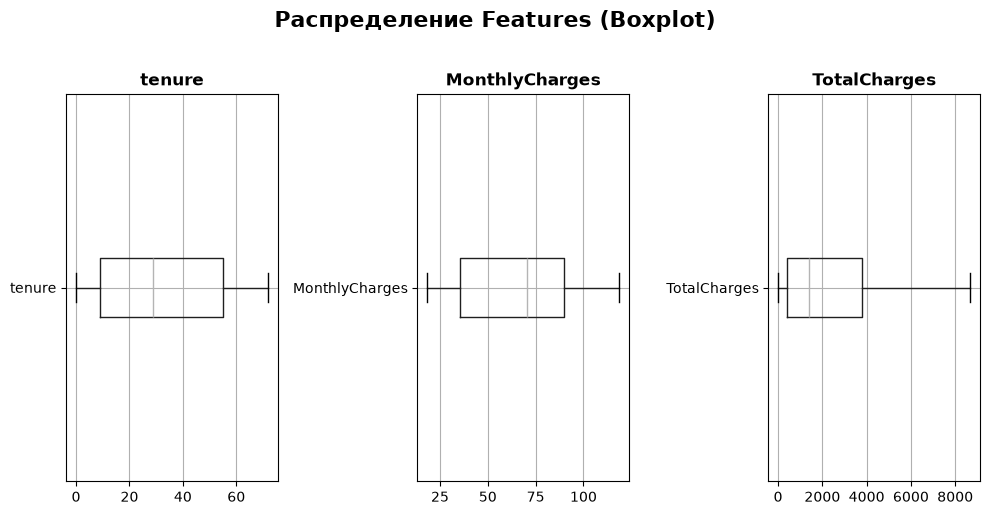

In [41]:
# features для анализа выбросов
features = ['tenure','MonthlyCharges','TotalCharges']

# Преобразование TotalCharges в числовой тип
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Boxplot для features
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
axes = axes.flatten()

for idx, col in enumerate(features):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение Features (Boxplot)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Анализ выбросов:**

| Признак | Выбросы | 
|---------|---------|
| **tenure** | Отсутствуют | 
| **MonthlyCharges** | Отсутствуют |
| **TotalCharges** | Отсутствуют |

In [42]:
# Соотношение количества услуг и ежемесячного платежа.
# Гипотеза: если подключенных услуг много, а ежемесячный платеж маленький, то клиент уже был удержан.

services = [ 'PhoneService',
            'MultipleLines',
             'InternetService',
             'OnlineSecurity',
             'OnlineBackup',
             'DeviceProtection',
             'TechSupport',
             'StreamingTV',
             'StreamingMovies'
             ]
for col in services:
  if col == 'InternetService':
    df[col] = df[col].apply(lambda x: 0 if x == 'No' else 1)
  else:
    df[col] = df[col].apply(lambda x: 1 if x == 'Yes' else 0)

df['NumServices'] = df[services].sum(axis=1)

df['PricePerService'] = df['MonthlyCharges'] / df['NumServices']

print(df[[ 'MonthlyCharges',
          'NumServices',
           'PricePerService',
           'PhoneService',
           'InternetService',
           'StreamingTV' ]].head())

low_price_clients = df.query("PricePerService < 10")
high_price_clients = df.query("PricePerService > 100")

print("\nКлиенты с очень низкой ценой за услугу (<$10):")
print(low_price_clients[['customerID', 'MonthlyCharges', 'NumServices', 'PricePerService']])
print("\nКлиенты с очень высокой ценой за услугу (>$100):")
print(high_price_clients[['customerID', 'MonthlyCharges', 'NumServices', 'PricePerService']])

   MonthlyCharges  NumServices  PricePerService  PhoneService  \
0           29.85            2          14.9250             0   
1           56.95            4          14.2375             1   
2           53.85            4          13.4625             1   
3           42.30            4          10.5750             0   
4           70.70            2          35.3500             1   

   InternetService  StreamingTV  
0                1            0  
1                1            0  
2                1            0  
3                1            0  
4                1            0  

Клиенты с очень низкой ценой за услугу (<$10):
      customerID  MonthlyCharges  NumServices  PricePerService
43    4671-VJLCL           79.85            8         9.981250
131   6207-WIOLX           58.60            6         9.766667
140   3146-MSEGF           88.05            9         9.783333
167   5997-OPVFA           89.05            9         9.894444
206   6348-SNFUS           55.45          

<span style="color: #FF5733;">Вывод надо поправить</span>  

**Вывод**: 902 неудержанных абонента

# Одномерный анализ

### 5.1 Целевая переменная Churn

Сначала оцениваем доли ушедших и оставшихся клиентов. В исходных данных 5174 клиента не ушли, значит отток составляет около 26,5% (1869 из 7043). Классы умеренно несбалансированы: при построении модели accuracy сама по себе будет недостаточной метрикой.

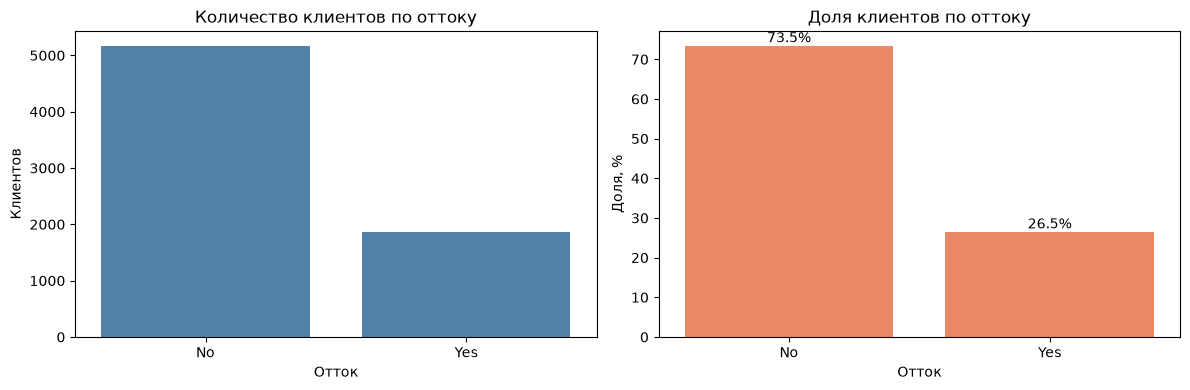

In [43]:
df_eda = df_before_substitute.copy(deep=True)

total_text = df_eda["TotalCharges"].astype("string").str.strip()
blank_total = total_text.eq("")
df_eda["TotalCharges"] = pd.to_numeric(total_text.mask(blank_total), errors="coerce")
df_eda.loc[blank_total & df_eda["tenure"].eq(0), "TotalCharges"] = 0
df_eda["MonthlyChargesChange"] = (
    df_eda["TotalCharges"] - df_eda["MonthlyCharges"] * df_eda["tenure"]
)

df_eda["ChurnFlag"] = df_eda["Churn"].map({"No": 0, "Yes": 1})
if df_eda["ChurnFlag"].isna().any():
    raise ValueError("В Churn обнаружены неизвестные категории")

churn_share = (
    df_eda["Churn"].value_counts(normalize=True)
    .reindex(["No", "Yes"], fill_value=0).mul(100)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_eda, x="Churn", order=["No", "Yes"],
              ax=axes[0], color="steelblue")
axes[0].set(title="Количество клиентов по оттоку", xlabel="Отток", ylabel="Клиентов")
sns.barplot(x=churn_share.index, y=churn_share.values, order=["No", "Yes"],
            ax=axes[1], color="coral")
axes[1].set(title="Доля клиентов по оттоку", xlabel="Отток", ylabel="Доля, %")
for bar in axes[1].patches:
    axes[1].annotate(f"{bar.get_height():.1f}%",
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Вывод:** отток — не редкое событие: уходит примерно каждый четвёртый клиент. В последующем анализе сравниваем именно долю `Churn = Yes` внутри сегментов, а не только число строк: сегменты разного размера нельзя корректно ранжировать по абсолютным количествам.

### 5.2 Числовые признаки

`tenure` — срок обслуживания в месяцах, `MonthlyCharges` — ежемесячный платёж, `TotalCharges` — накопленные платежи. `MonthlyChargesChange` рассчитан как `TotalCharges - MonthlyCharges × tenure`; он показывает разницу между фактическими накопленными платежами и оценкой при неизменной месячной цене. Для каждого показателя смотрим форму распределения, медиану и возможные крайние значения.

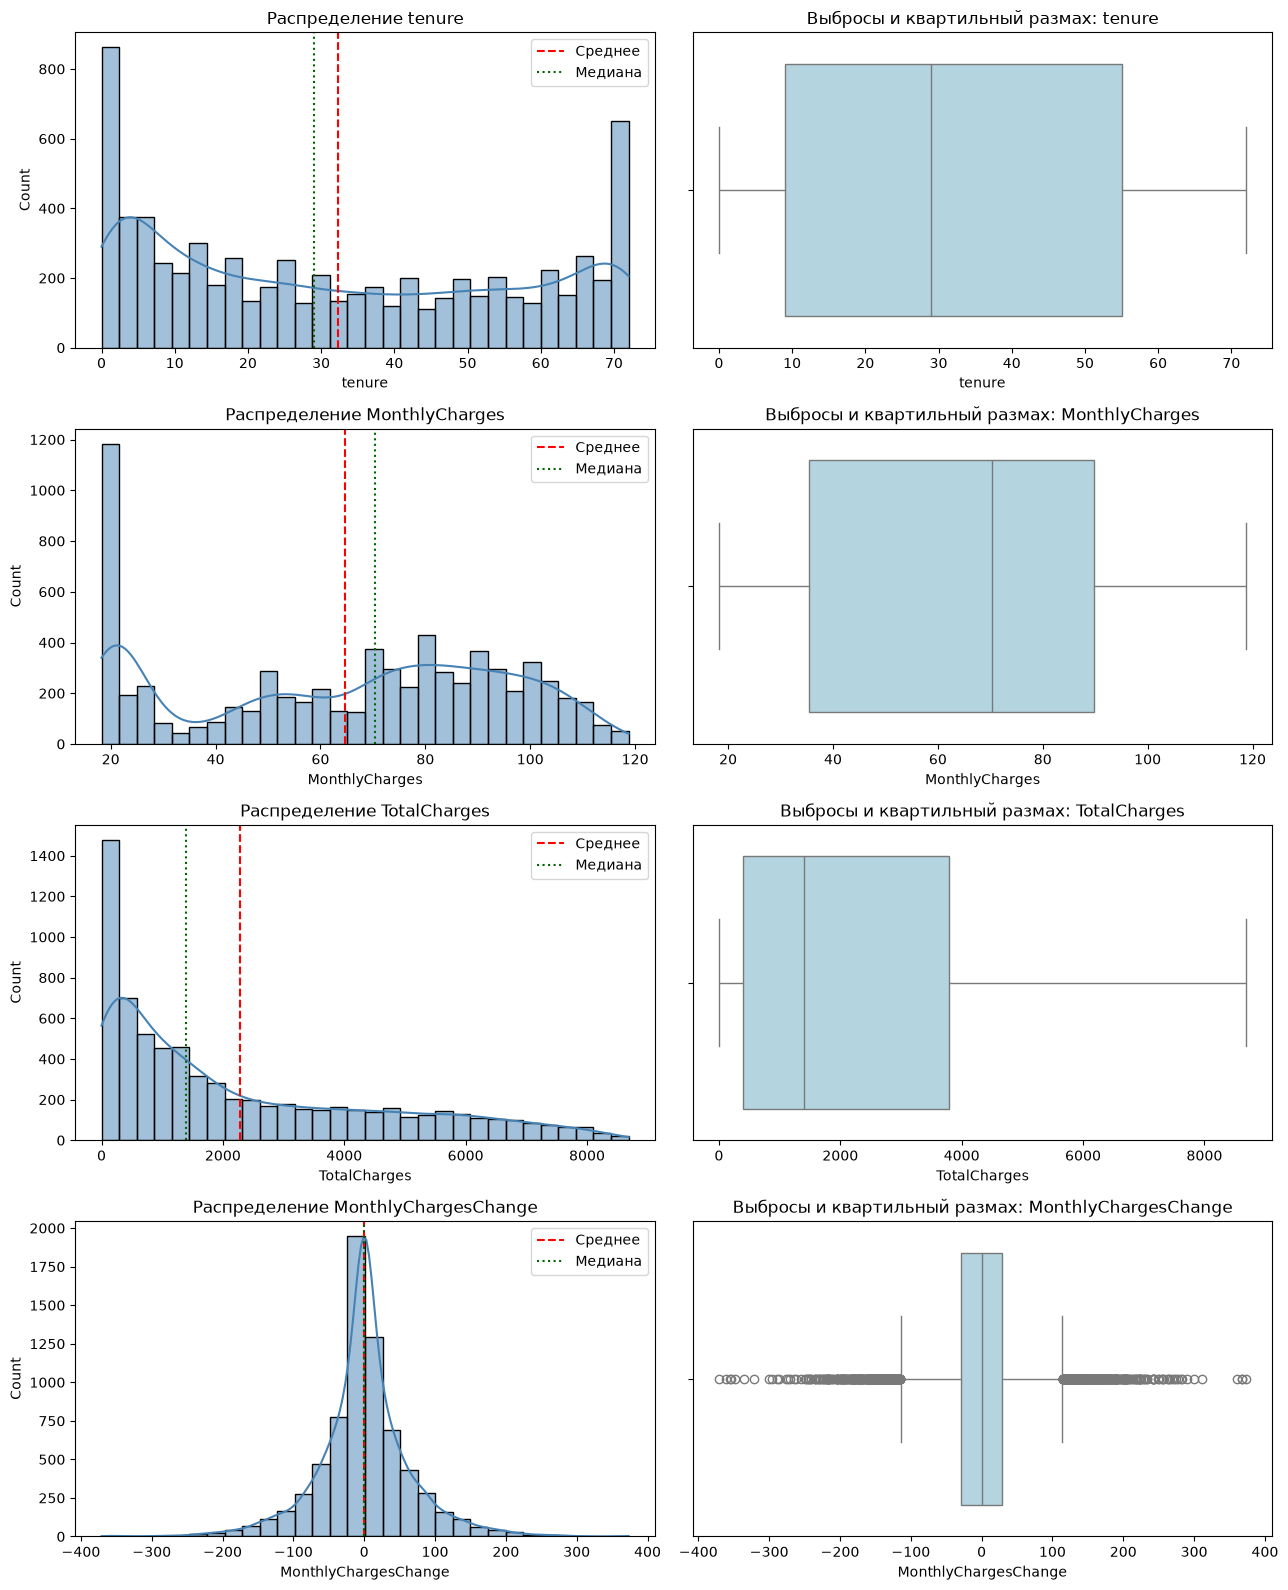

In [44]:
numeric_features = [
    'tenure', 'MonthlyCharges', 'TotalCharges', 'MonthlyChargesChange'
]

fig, axes = plt.subplots(len(numeric_features), 2, figsize=(13, 4 * len(numeric_features)))
for row, col in enumerate(numeric_features):
    sns.histplot(df_eda[col].dropna(), bins=30, kde=True, ax=axes[row, 0], color='steelblue')
    axes[row, 0].axvline(df_eda[col].mean(), color='red', linestyle='--', label='Среднее')
    axes[row, 0].axvline(df_eda[col].median(), color='darkgreen', linestyle=':', label='Медиана')
    axes[row, 0].set(title=f'Распределение {col}', xlabel=col)
    axes[row, 0].legend()
    sns.boxplot(x=df_eda[col], ax=axes[row, 1], color='lightblue')
    axes[row, 1].set(title=f'Выбросы и квартильный размах: {col}', xlabel=col)
plt.tight_layout()
plt.show()

**Выводы по форме распределений:** `tenure` имеет заметную концентрацию у новых клиентов и у клиентов с длительным сроком обслуживания; это признак с потенциально сильной связью с оттоком. `TotalCharges` обычно имеет правый хвост, поскольку растёт вместе со сроком обслуживания и ежемесячным платежом. Высокие значения на boxplot не следует автоматически удалять: они могут отражать длительное обслуживание или дорогой тариф.

### 5.3 Категориальные признаки

Для каждого категориального признака считаем долю оттока внутри категории. Графики по всем признакам собраны в сетку 4 × 4, чтобы можно было сравнить картину целиком.

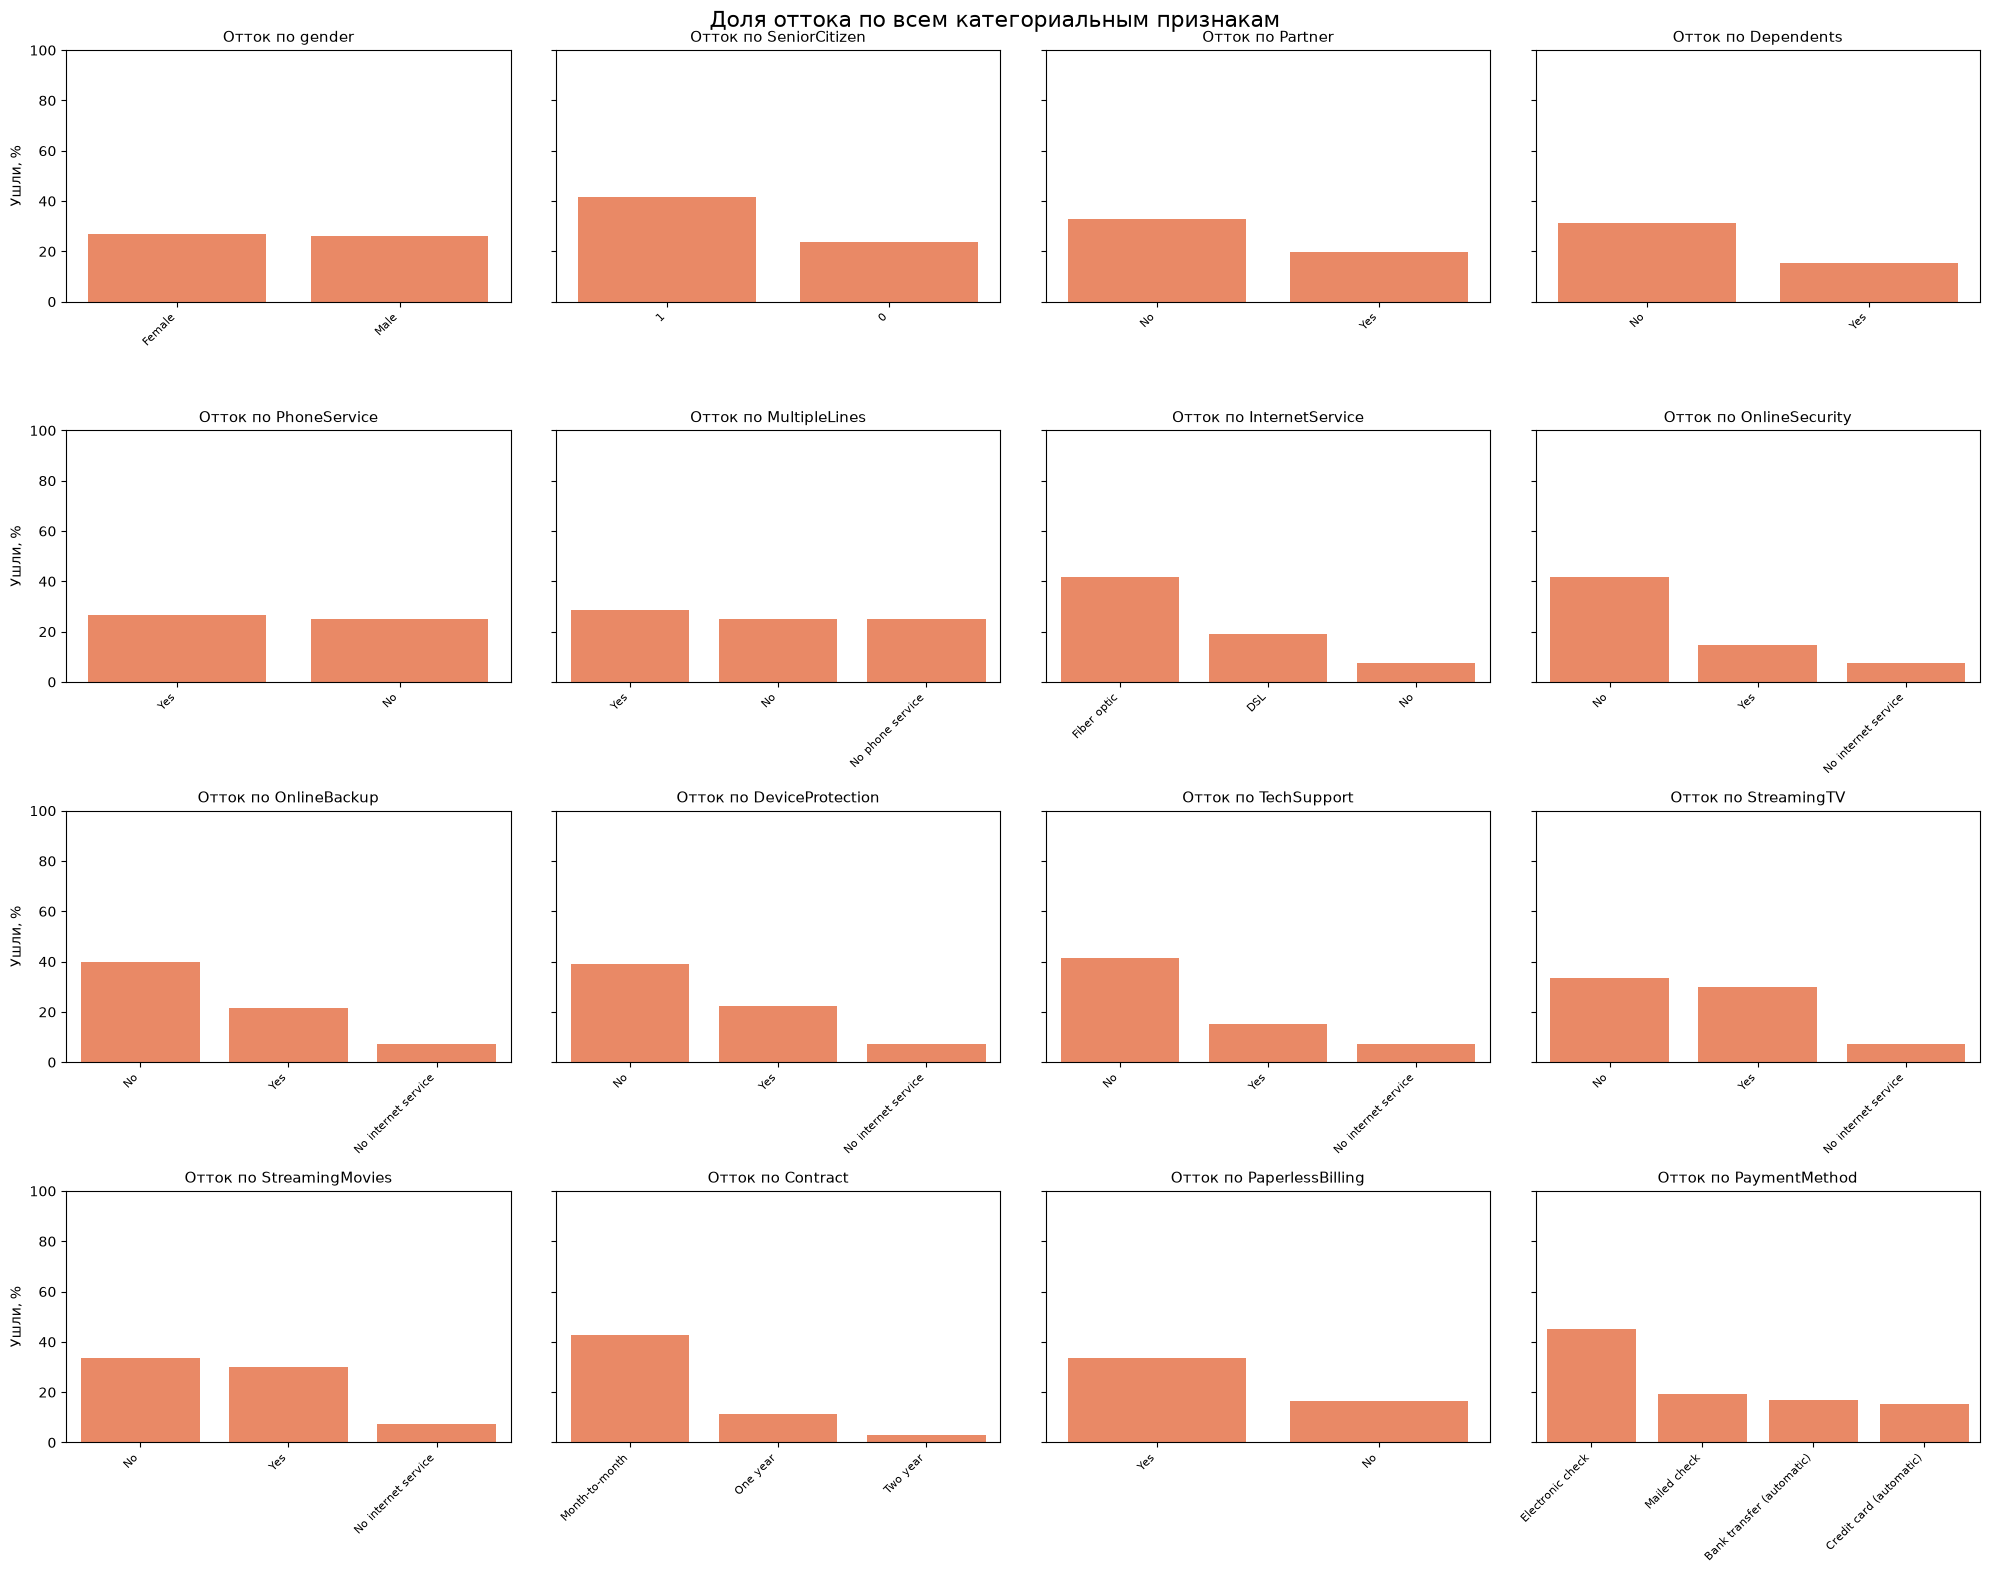

In [45]:
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

fig, axes = plt.subplots(4, 4, figsize=(20, 16), sharey=True)
for ax, col in zip(axes.flat, categorical_features):
    rates = (df_eda.groupby(col, observed=False)['ChurnFlag']
             .mean().mul(100).dropna().sort_values(ascending=False))
    sns.barplot(x=rates.index.astype(str), y=rates.values,
                ax=ax, color='coral')
    ax.set_title(f'Отток по {col}', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Ушли, %' if ax in axes[:, 0] else '')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_ha('right')
fig.suptitle('Доля оттока по всем категориальным признакам', fontsize=16)
plt.tight_layout()
plt.show()

**Ожидаемый содержательный результат:** самый заметный сегментный разрыв обычно виден для `Contract`: у клиентов с помесячным договором доля оттока намного выше, чем у клиентов с годовыми и двухлетними договорами. Повышенный отток также часто наблюдается у клиентов с оптоволоконным интернетом, электронным чеком и без `TechSupport`/`OnlineSecurity`. Это ассоциации в наблюдательных данных, а не доказательство причинности. Категории `No internet service` и `No phone service` — отдельные осмысленные значения, не пропуски.

# Многомерный анализ

## 6.1 Связи числовых признаков и оттока

Сравниваем распределения числовых показателей между ушедшими и оставшимися клиентами. Корреляция Спирмена полезна как оценка монотонных связей и менее чувствительна к форме распределения, чем обычная линейная корреляция Пирсона.

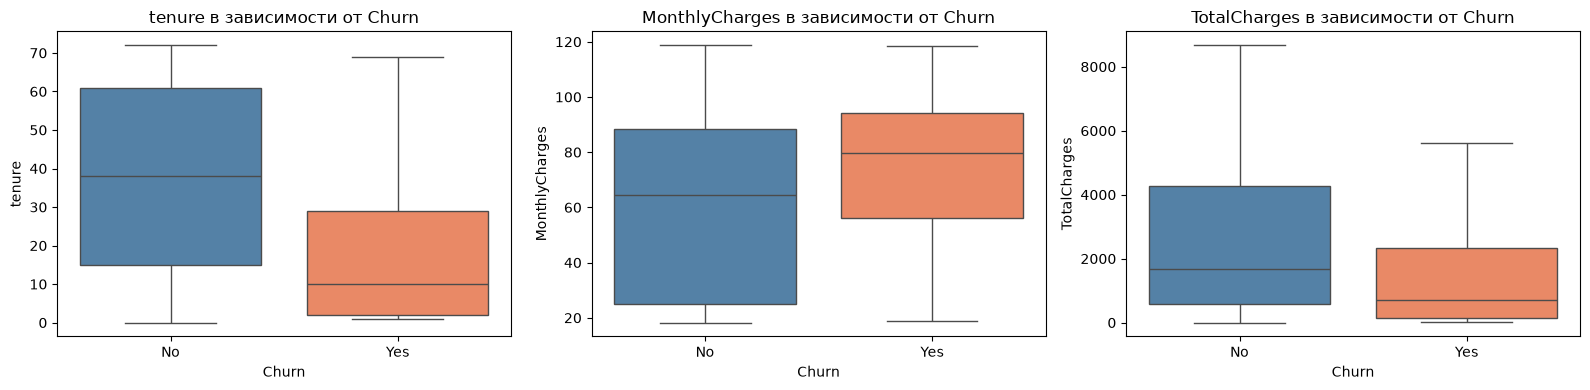

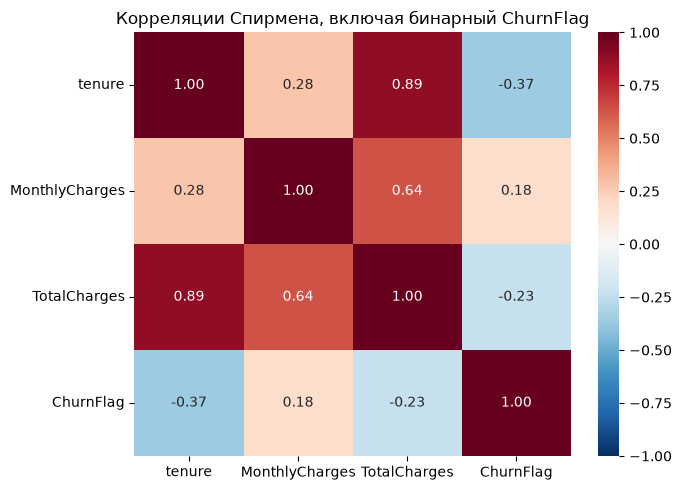

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, numeric_features):
    sns.boxplot(data=df_eda, x='Churn', y=col,
                order=['No', 'Yes'], hue='Churn', hue_order=['No', 'Yes'],
                ax=ax, showfliers=False,
                palette={'No': 'steelblue', 'Yes': 'coral'},
                legend=False)
    ax.set_title(f'{col} в зависимости от Churn')
plt.tight_layout()
plt.show()

spearman = df_eda[['tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].corr(method='spearman')
plt.figure(figsize=(7, 5))
sns.heatmap(spearman, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Корреляции Спирмена, включая бинарный ChurnFlag')
plt.tight_layout()
plt.show()

**Интерпретация:** наиболее ожидаемый паттерн — меньший `tenure` среди ушедших клиентов. `TotalCharges` нельзя трактовать отдельно от `tenure`: накопленная сумма по смыслу зависит от срока обслуживания. Поэтому для удержания клиентов полезнее изучать сочетания короткого срока, типа договора, тарифа и ежемесячного платежа, а не делать вывод по одной корреляции.

## 6.2 Риск оттока по сроку и ежемесячному платежу

Группировка показывает нелинейность и сегменты риска. Квантили `MonthlyCharges` используются, чтобы получить сопоставимые по размеру группы.

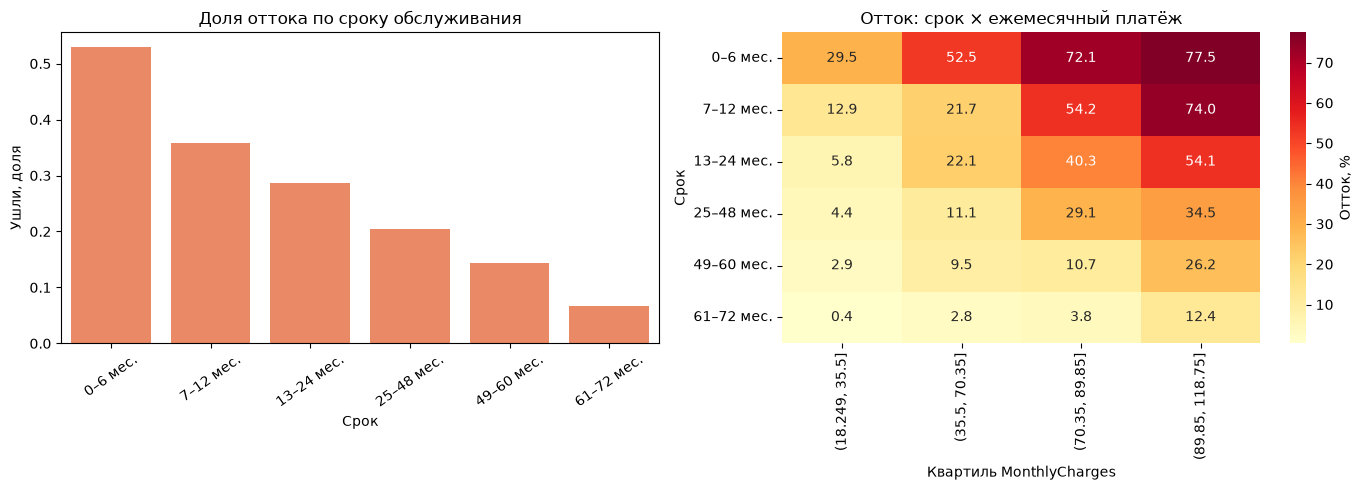

In [47]:
df_eda['TenureGroup'] = pd.cut(
    df_eda['tenure'], bins=[-1, 6, 12, 24, 48, 60, 72],
    labels=['0–6 мес.', '7–12 мес.', '13–24 мес.', '25–48 мес.', '49–60 мес.', '61–72 мес.'],
    include_lowest=True
)
df_eda['MonthlyChargeGroup'] = pd.qcut(
    df_eda['MonthlyCharges'], q=4, duplicates='drop'
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tenure_risk = (df_eda.groupby('TenureGroup', observed=False)['ChurnFlag']
               .agg(['mean', 'size']).reset_index())
sns.barplot(data=tenure_risk, x='TenureGroup', y='mean', ax=axes[0], color='coral')
axes[0].set(title='Доля оттока по сроку обслуживания', xlabel='Срок', ylabel='Ушли, доля')
axes[0].tick_params(axis='x', rotation=35)

charge_tenure = (df_eda.pivot_table(index='TenureGroup', columns='MonthlyChargeGroup',
                                    values='ChurnFlag', aggfunc='mean', observed=False) * 100)
sns.heatmap(charge_tenure, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Отток, %'})
axes[1].set(title='Отток: срок × ежемесячный платёж', xlabel='Квартиль MonthlyCharges', ylabel='Срок')
plt.tight_layout()
plt.show()

**Выводы:** в этом наборе данных основной ожидаемый паттерн — самый высокий отток у клиентов с коротким сроком обслуживания; по мере роста `tenure` риск обычно снижается. Тепловая карта помогает проверить, усиливается ли отток среди клиентов с высокими `MonthlyCharges` внутри каждой группы стажа. Если цветовые различия по квартилям платежа слабее, чем по стажу, то стаж разделяет клиентов заметнее, чем сама сумма ежемесячного платежа.

## 6.3 Сочетания категориальных факторов

Проверяем совместное распределение договора и интернет-услуги. На тепловой карте показываем долю оттока внутри каждой комбинации; малые сегменты стоит трактовать осторожно.

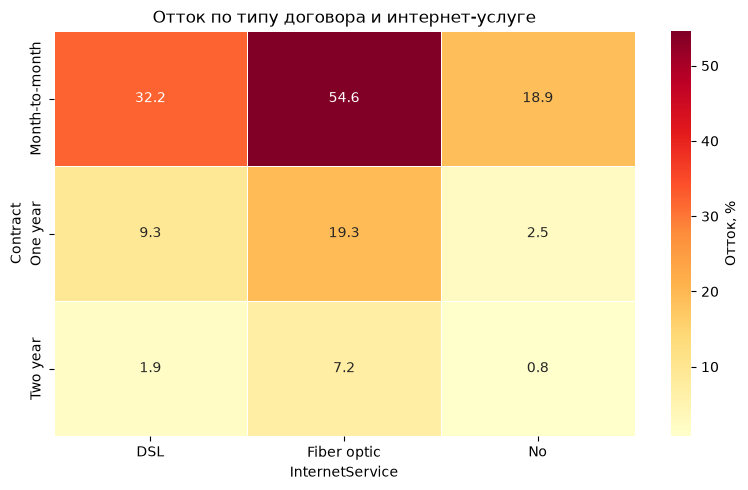

In [48]:
segment = (
    df_eda.pivot_table(index='Contract', columns='InternetService',
                       values='ChurnFlag', aggfunc='mean', observed=False) * 100
)
plt.figure(figsize=(8, 5))
sns.heatmap(segment, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=.5,
            cbar_kws={'label': 'Отток, %'})
plt.title('Отток по типу договора и интернет-услуге')
plt.tight_layout()
plt.show()

**Выводы:** наиболее заметное различие наблюдается между типами договора: отток выше у клиентов с помесячным договором и ниже у клиентов с контрактом на год или два. По типу интернета отток обычно выше у пользователей оптоволокна, чем у клиентов без интернета; сравнение `DSL` с оптоволокном показывает, меняется ли разрыв в зависимости от срока договора. Самые высокие доли часто наблюдаются в сочетании помесячного договора и оптоволокна, а длинный договор связан с более низким оттоком при разных типах интернета.

Для оценки силы связи между категориальными признаками используем коэффициент V Крамера. Он принимает значения от 0 до 1: чем ближе значение к 0, тем слабее связь, а чем ближе к 1 — тем сильнее. Коэффициент позволяет сравнивать пары признаков, например тип договора и наличие оттока. Сам по себе V Крамера не показывает направление связи и не доказывает причинно-следственную зависимость, поэтому для интерпретации отдельных групп дополнительно рассматривались доли оттока.

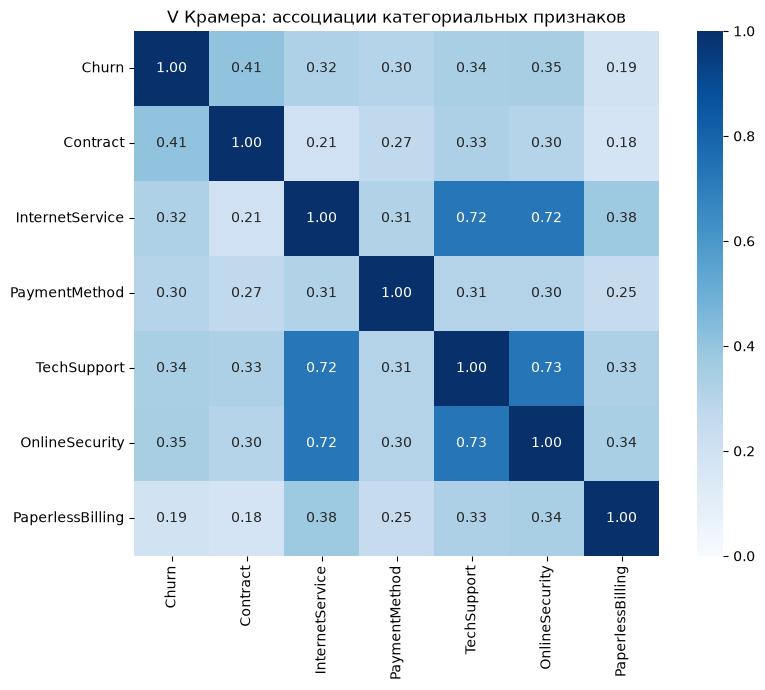

In [49]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.empty or min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

assoc_features = ['Churn', 'Contract', 'InternetService', 'PaymentMethod',
                  'TechSupport', 'OnlineSecurity', 'PaperlessBilling']
cramers = pd.DataFrame(index=assoc_features, columns=assoc_features, dtype=float)
for col1 in assoc_features:
    for col2 in assoc_features:
        cramers.loc[col1, col2] = cramers_v(df_eda[col1], df_eda[col2])

plt.figure(figsize=(9, 7))
sns.heatmap(cramers, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True)
plt.title('V Крамера: ассоциации категориальных признаков')
plt.tight_layout()
plt.show()

По матрице V Крамера наиболее сильная связь с оттоком наблюдается у типа договора (`Contract`, V = 0,41). Далее следуют наличие онлайн-защиты (`OnlineSecurity`, 0,35), технической поддержки (`TechSupport`, 0,34), тип интернет-подключения (`InternetService`, 0,32) и способ оплаты (`PaymentMethod`, 0,30). Связь `PaperlessBilling` с оттоком слабее среди рассмотренных признаков (V = 0,19).

Между некоторыми услугами также обнаружена сильная ассоциация: V составляет 0,72 для пар `InternetService`—`TechSupport` и `InternetService`—`OnlineSecurity`, а для `TechSupport`—`OnlineSecurity` — 0,73. Значит, эти признаки могут нести частично совпадающую информацию.

# Сегментный анализ

## 7.1 Отток по числу базовых подключённых услуг

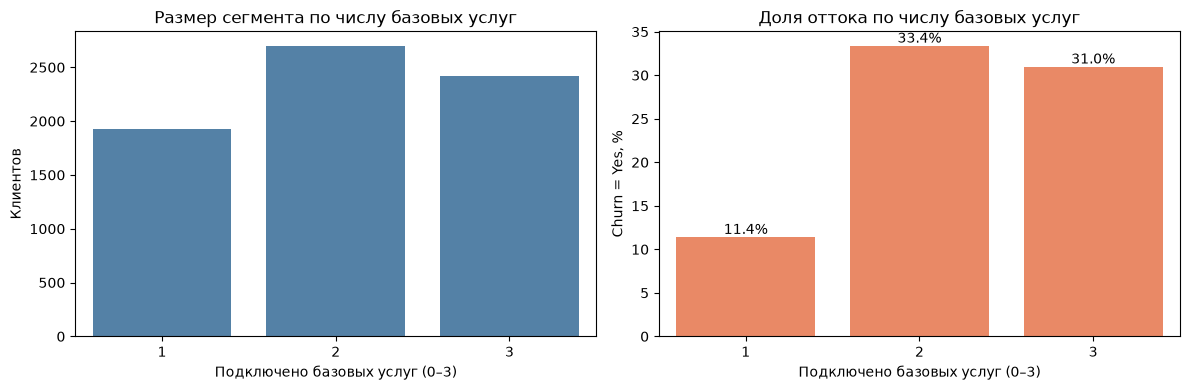

In [50]:
df_eda["HasInternet"] = df_eda["InternetService"].isin(
    ["DSL", "Fiber optic"]
).astype(int)
df_eda["HasPhone"] = df_eda["PhoneService"].eq("Yes").astype(int)
df_eda["HasTV"] = df_eda["StreamingTV"].eq("Yes").astype(int)

base_service_flags = ["HasInternet", "HasPhone", "HasTV"]
df_eda["NumBasicServices"] = df_eda[base_service_flags].sum(axis=1)
basic_service_summary = (
    df_eda.groupby('NumBasicServices', observed=False)
    .agg(Клиентов=('ChurnFlag', 'size'),
         Ушли=('ChurnFlag', 'sum'),
         Доля_оттока=('ChurnFlag', 'mean'))
    .reset_index()
)
basic_service_summary['Доля_оттока_pct'] = basic_service_summary['Доля_оттока'] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=basic_service_summary, x='NumBasicServices', y='Клиентов',
            ax=axes[0], color='steelblue')
axes[0].set(title='Размер сегмента по числу базовых услуг',
            xlabel='Подключено базовых услуг (0–3)', ylabel='Клиентов')
sns.barplot(data=basic_service_summary, x='NumBasicServices', y='Доля_оттока_pct',
            ax=axes[1], color='coral')
axes[1].set(title='Доля оттока по числу базовых услуг',
            xlabel='Подключено базовых услуг (0–3)', ylabel='Churn = Yes, %')
for bar in axes[1].patches:
    axes[1].annotate(f'{bar.get_height():.1f}%',
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 7.2 Социально-демографические сегменты оттока

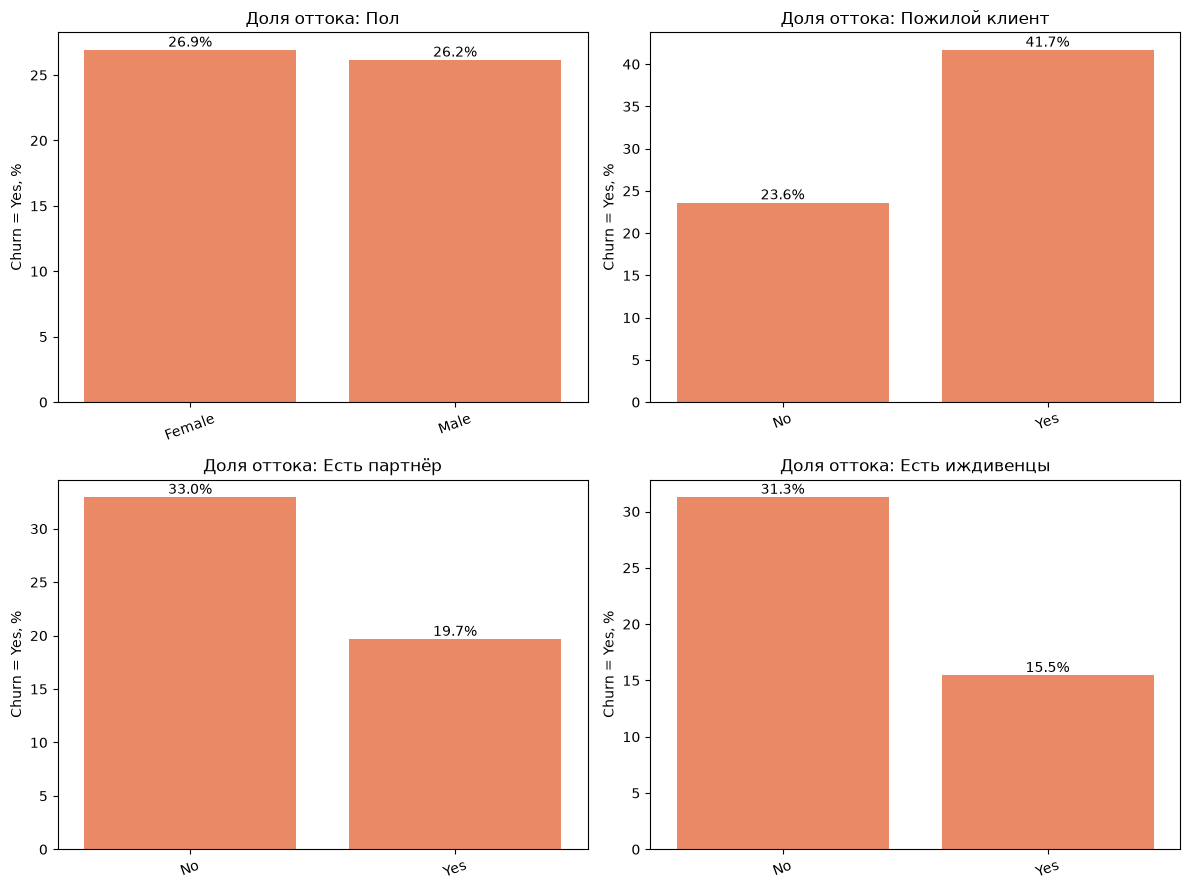

In [51]:
df_eda['SeniorCitizenGroup'] = df_eda['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
demo_features = ['gender', 'SeniorCitizenGroup', 'Partner', 'Dependents']
demo_labels = {
    'gender': 'Пол', 'SeniorCitizenGroup': 'Пожилой клиент',
    'Partner': 'Есть партнёр', 'Dependents': 'Есть иждивенцы'
}

demo_summaries = {}
for col in demo_features:
    summary = (
        df_eda.groupby(col, dropna=False, observed=False)
        .agg(Клиентов=('ChurnFlag', 'size'),
             Ушли=('ChurnFlag', 'sum'),
             Доля_оттока=('ChurnFlag', 'mean'))
        .reset_index()
    )
    summary['Доля_оттока_pct'] = summary['Доля_оттока'] * 100
    demo_summaries[col] = summary

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, demo_features):
    summary = demo_summaries[col]
    sns.barplot(data=summary, x=col, y='Доля_оттока_pct', ax=ax, color='coral')
    ax.set(title=f"Доля оттока: {demo_labels[col]}",
           xlabel='', ylabel='Churn = Yes, %')
    ax.tick_params(axis='x', rotation=20)
    for bar in ax.patches:
        ax.annotate(f'{bar.get_height():.1f}%',
                    (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 7.3 Сочетания сегментов

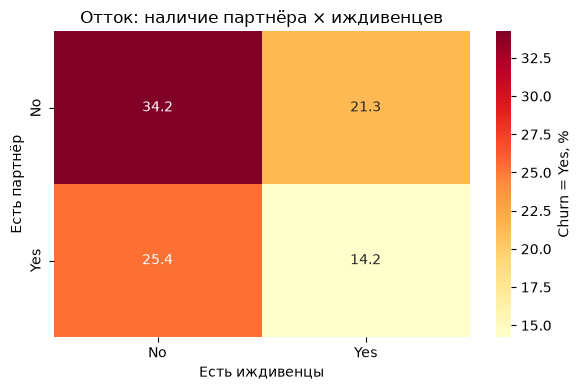

In [53]:
demo_joint_churn = (
    df_eda.pivot_table(index='Partner', columns='Dependents', values='ChurnFlag',
                       aggfunc='mean', observed=False) * 100
)

plt.figure(figsize=(6, 4))
sns.heatmap(demo_joint_churn, annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Churn = Yes, %'})
plt.title('Отток: наличие партнёра × иждивенцев')
plt.xlabel('Есть иждивенцы')
plt.ylabel('Есть партнёр')
plt.tight_layout()
plt.show()

# 8. Сводка итогового датафрейма df_eda

## 8.1. Первый взгляд на данные

In [56]:
display(df_eda.head())
display(df_eda.sample(5, random_state=42))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,Churn,MonthlyChargesChange,ChurnFlag,TenureGroup,MonthlyChargeGroup,HasInternet,HasPhone,HasTV,NumBasicServices,SeniorCitizenGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,0.0,0,0–6 мес.,"(18.249, 35.5]",1,0,0,1,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,-46.8,0,25–48 мес.,"(35.5, 70.35]",1,1,0,2,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Yes,0.45,1,0–6 мес.,"(35.5, 70.35]",1,1,0,2,No
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,-62.75,0,25–48 мес.,"(35.5, 70.35]",1,0,0,1,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Yes,10.25,1,0–6 мес.,"(70.35, 89.85]",1,1,0,2,No


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,Churn,MonthlyChargesChange,ChurnFlag,TenureGroup,MonthlyChargeGroup,HasInternet,HasPhone,HasTV,NumBasicServices,SeniorCitizenGroup
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Yes,0.0,1,0–6 мес.,"(18.249, 35.5]",1,0,0,1,No
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No,-38.8,0,25–48 мес.,"(18.249, 35.5]",0,1,0,1,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No,25.5,0,49–60 мес.,"(18.249, 35.5]",0,1,0,1,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,0.0,1,0–6 мес.,"(70.35, 89.85]",1,1,0,2,No
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,-126.75,0,61–72 мес.,"(35.5, 70.35]",1,1,0,2,No


## 8.2. Технический паспорт данных

In [55]:
df_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   customerID            7043 non-null   str     
 1   gender                7043 non-null   str     
 2   SeniorCitizen         7043 non-null   int64   
 3   Partner               7043 non-null   str     
 4   Dependents            7043 non-null   str     
 5   tenure                7043 non-null   int64   
 6   PhoneService          7043 non-null   str     
 7   MultipleLines         7043 non-null   str     
 8   InternetService       7043 non-null   str     
 9   OnlineSecurity        7043 non-null   str     
 10  OnlineBackup          7043 non-null   str     
 11  DeviceProtection      7043 non-null   str     
 12  TechSupport           7043 non-null   str     
 13  StreamingTV           7043 non-null   str     
 14  StreamingMovies       7043 non-null   str     
 15  Contract       

---

# Часть 2. Построение модели прогнозирования оттока

После проведения разведочного анализа данных (EDA) переходим к машинному обучению. На этом этапе мы:
1. Подготовим таблицу признаков `X` и целевую переменную `y` (переведём текстовые категории в числа 0 и 1)
2. Разделим данные на обучающую (`Train`) и тестовую (`Test`) выборки со стратификацией по целевой переменной (`stratify=y`)
3. Выполним стандартизацию числовых признаков (`StandardScaler`)
4. Обучим и сравним baseline-модели: простейший ориентир `DummyClassifier` и `LogisticRegression` (обычную и с балансировкой классов `class_weight='balanced'`)


## 9. Подготовка признаков (`X`) и целевой переменной (`y`)

В итоговом датафрейме `df_eda` сейчас 30 столбцов (включая идентификатор `customerID`, текстовый таргет `Churn` и вспомогательные группы, которые создавались только для  EDA). Отберём для моделирования только содержательные признаки:
- **Целевая переменная (`y`):** `ChurnFlag` (`0` - клиент остался, `1` - клиент ушёл)
- **Числовые признаки (3 шт.):** `tenure`, `MonthlyCharges`, `MonthlyChargesChange` (`TotalCharges` исключаем, так как мы заменили его на `MonthlyChargesChange`, чтобы избежать сильной линейной зависимости со "стажем" и ежемесячным платежом)
- **Категориальные признаки (16 шт.):** пол, семейное положение, подключённые услуги, тип контракта и способ оплаты

Также перед кодированием упростим дополнительные услуги: значения `'No internet service'` и `'No phone service'` заменим на `'No'`, поскольку сам факт наличия интернета или телефонии уже отражён в столбцах `InternetService` и `PhoneService`



In [56]:
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod',
]
numeric_features = ['tenure', 'MonthlyCharges', 'MonthlyChargesChange']

df_model = df_eda[categorical_features + numeric_features].copy()
df_model[numeric_features] = df_model[numeric_features].astype(float)

# Посмотрим на данные ДО кодирования категориальных признаков
print('Размер таблицы до кодирования:', df_model.shape)
display(df_model.head(3))


Размер таблицы до кодирования: (7043, 19)


,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,tenure,MonthlyCharges,MonthlyChargesChange
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,1.0,29.85,0.00
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,34.0,56.95,-46.80
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,2.0,53.85,0.45


In [57]:
# Заменяем дублирующие значения в дополнительных услугах на 'No'
internet_cols = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
]
df_model[internet_cols] = df_model[internet_cols].replace('No internet service', 'No')
df_model['MultipleLines'] = df_model['MultipleLines'].replace('No phone service', 'No')

# Переводим категориальные признаки в бинарные столбцы 0/1 (One-Hot Encoding)
X = pd.get_dummies(df_model, columns=categorical_features, drop_first=True, dtype=int)
y = df_eda['ChurnFlag']

print('Размер матрицы признаков X после get_dummies:', X.shape)
print('Размер целевой переменной y:', y.shape)
print('Пропусков в X:', X.isna().sum().sum())
display(X.head())


Размер матрицы признаков X после get_dummies: (7043, 23)
Размер целевой переменной y: (7043,)
Пропусков в X: 0


,tenure,MonthlyCharges,MonthlyChargesChange,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.0,29.85,0.00,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,34.0,56.95,-46.80,1,0,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,1
2,2.0,53.85,0.45,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,45.0,42.30,-62.75,1,0,0,0,0,0,0,...,1,1,0,0,1,0,0,0,0,0
4,2.0,70.70,10.25,0,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0


In [ ]:
# Посмотрим список всех 23 итоговых признаков и статистику числовых столбцов
print('Список признаков в X:')
print(list(X.columns))

print('\nСтатистика числовых признаков (в исходных единицах измерения):')
display(X[numeric_features].describe().round(2))


Список признаков в X:
['tenure', 'MonthlyCharges', 'MonthlyChargesChange', 'gender_Male', 'SeniorCitizen_1', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

Статистика числовых признаков (в исходных единицах измерения):


,tenure,MonthlyCharges,MonthlyChargesChange
count,7043.00,7043.00,7043.00
mean,32.37,64.76,0.15
std,24.56,30.09,67.20
min,0.00,18.25,-370.85
25%,9.00,35.50,-28.60
50%,29.00,70.35,0.00
75%,55.00,89.85,28.50
max,72.00,118.75,373.25


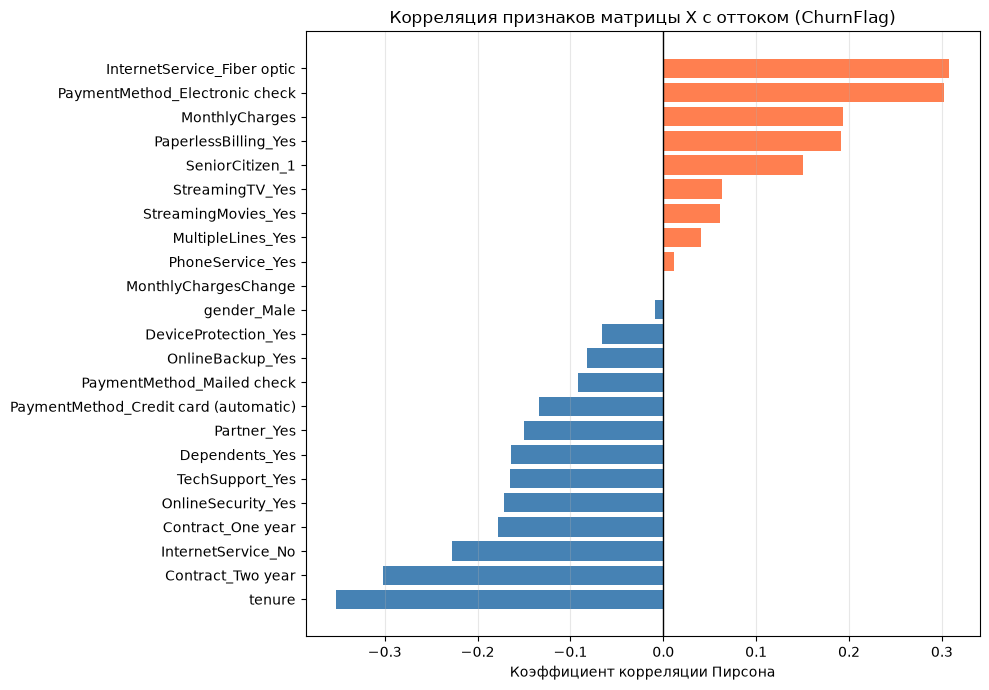

In [59]:
# Посмотрим, какие признаки в готовой матрице X сильнее всего коррелируют с целевой переменной y
corr_with_target = X.corrwith(y).sort_values()

plt.figure(figsize=(10, 7))
colors = ['steelblue' if val < 0 else 'coral' for val in corr_with_target]
plt.barh(corr_with_target.index, corr_with_target.values, color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Корреляция признаков матрицы X с оттоком (ChurnFlag)')
plt.xlabel('Коэффициент корреляции Пирсона')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


**Вывод по шагу 9:**
- Сформирована матрица признаков `X` размером **7 043 строки × 23 столбца** и целевой вектор `y` (`ChurnFlag`). Пропусков в данных нет, все признаки приведены к числовому виду
- По таблице `.describe()` видно, что числовые признаки пока имеют **сильно разный масштаб**: `tenure` меняется от `0` до `72` мес., `MonthlyCharges` - от `18.25` до `118.75` долл., а `MonthlyChargesChange` - от `-373` до `+373`. Поэтому перед обучением линейной модели их обязательно нужно стандартизировать
- По графику корреляций уже видна логичная картина: сильнее всего с уходом положительно связаны `InternetService_Fiber optic`, `PaymentMethod_Electronic check` и `PaperlessBilling_Yes`, а сильнее всего против оттока работают `tenure` и длительные контракты (`Contract_Two year`, `Contract_One year`)


## 10. Разделение выборки (`train_test_split`, `stratify=y`) и стандартизация

Разделим выборку на обучающую (`Train`, 80%) и тестовую (`Test`, 20%). На `Train` модель будет учиться, а на `Test` (который модель не видела при обучении) мы честно проверим качество прогноза

Так как классы у нас несбалансированы (~26,5% ушедших против ~73,5% оставшихся), обязательно используем параметр **`stratify=y`** - он гарантирует, что доля оттока в `Train` и `Test` будет точно такой же, как во всём датасете


In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Сводная таблица по разбиению выборки
split_table = pd.DataFrame({
    'Выборка': ['Весь датасет', 'Train (80%)', 'Test (20%)'],
    'Всего клиентов': [len(y), len(y_train), len(y_test)],
    'Остались (0)': [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    'Ушли (1)': [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
    'Доля оттока, %': [
        round(y.mean() * 100, 2),
        round(y_train.mean() * 100, 2),
        round(y_test.mean() * 100, 2),
    ],
})

display(split_table)


,Выборка,Всего клиентов,Остались (0),Ушли (1),"Доля оттока, %"
0,Весь датасет,7043,5174,1869,26.54
1,Train (80%),5634,4139,1495,26.54
2,Test (20%),1409,1035,374,26.54


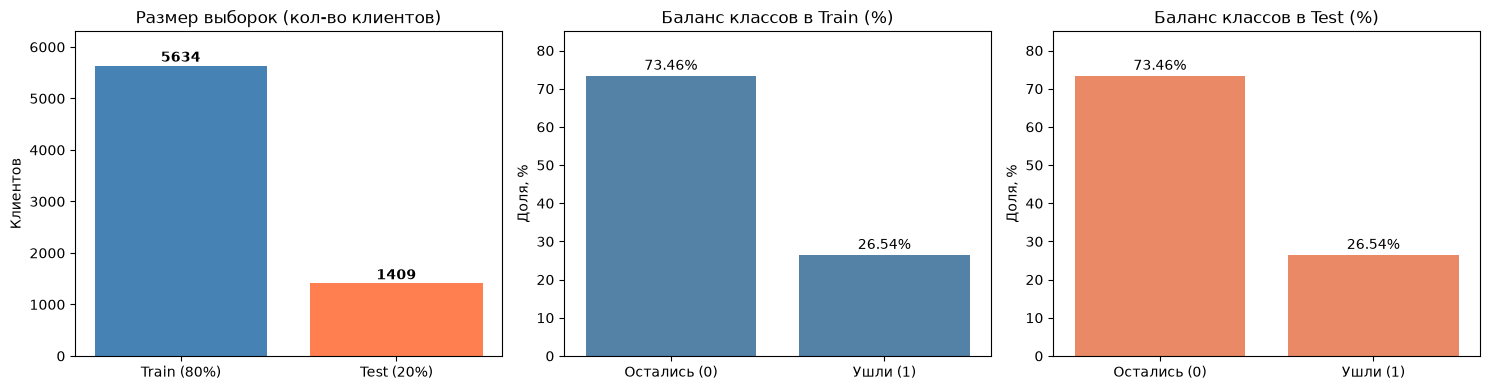

In [61]:
# Визуализируем размер выборок и сохранение баланса классов после стратификации
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Количество клиентов в Train и Test
axes[0].bar(['Train (80%)', 'Test (20%)'], [len(X_train), len(X_test)], color=['steelblue', 'coral'])
axes[0].set_title('Размер выборок (кол-во клиентов)')
axes[0].set_ylabel('Клиентов')
for i, v in enumerate([len(X_train), len(X_test)]):
    axes[0].text(i, v + 80, str(v), ha='center', fontweight='bold')
axes[0].set_ylim(0, 6300)

# 2. Доли классов в Train
train_shares = y_train.value_counts(normalize=True) * 100
sns.barplot(x=['Остались (0)', 'Ушли (1)'], y=train_shares.values, ax=axes[1], color='steelblue')
axes[1].set_title('Баланс классов в Train (%)')
axes[1].set_ylabel('Доля, %')
axes[1].set_ylim(0, 85)
for i, v in enumerate(train_shares.values):
    axes[1].text(i, v + 1.5, f'{v:.2f}%', ha='center')

# 3. Доли классов в Test
test_shares = y_test.value_counts(normalize=True) * 100
sns.barplot(x=['Остались (0)', 'Ушли (1)'], y=test_shares.values, ax=axes[2], color='coral')
axes[2].set_title('Баланс классов в Test (%)')
axes[2].set_ylabel('Доля, %')
axes[2].set_ylim(0, 85)
for i, v in enumerate(test_shares.values):
    axes[2].text(i, v + 1.5, f'{v:.2f}%', ha='center')

plt.tight_layout()
plt.show()


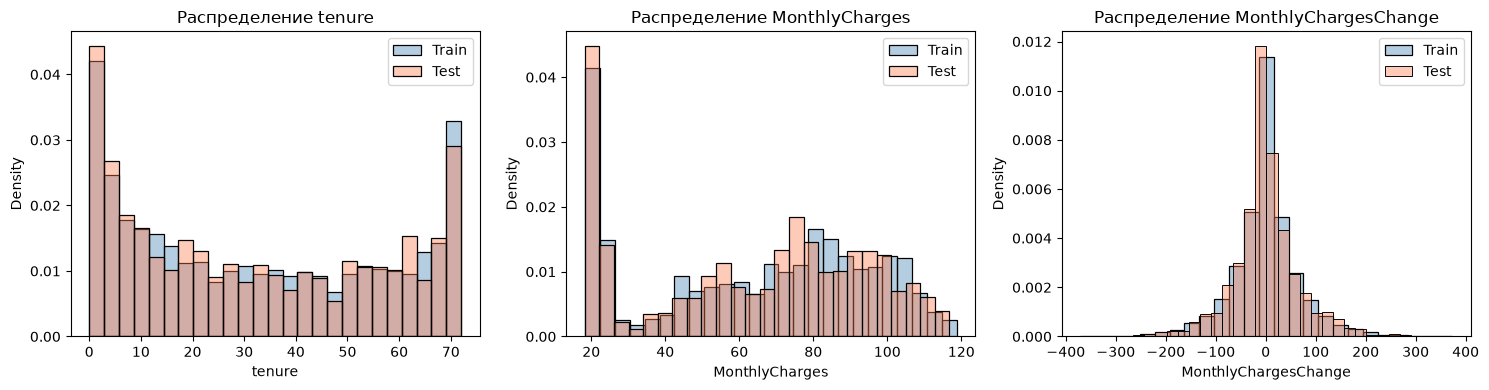

In [62]:
# Дополнительно убедимся, что числовые признаки распределены в Train и Test одинаково
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric_features):
    sns.histplot(X_train[col], bins=25, stat='density', color='steelblue', alpha=0.4, label='Train', ax=ax)
    sns.histplot(X_test[col], bins=25, stat='density', color='coral', alpha=0.4, label='Test', ax=ax)
    ax.set_title(f'Распределение {col}')
    ax.legend()

plt.tight_layout()
plt.show()


**Вывод по разбиению выборки:**
- В обучающую выборку `Train` попало **5 634** клиента (4 139 остались и 1 495 ушли), в тестовую `Test` - **1 409** клиентов (1 035 остались и 374 ушли)
- Стратификация сработала точно: доля ушедших клиентов составляет **26,54%** и в `Train`, и в `Test`
- Гистограммы подтверждают, что распределения числовых признаков `tenure`, `MonthlyCharges` и `MonthlyChargesChange` в обеих выборках практически совпадают


### 10.1. Стандартизация числовых признаков (`StandardScaler`)

Теперь, приведём 3 числовых признака к единому масштабу с помощью `StandardScaler` (среднее значение станет `0`, а стандартное отклонение - `1`)

обучаем `scaler` (`fit_transform`) **только на `X_train`**, а к `X_test` применяем уже готовый `transform`


In [63]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

print('Пример строк X_train_scaled после стандартизации числовых столбцов:')
display(X_train_scaled.head(3).round(3))

print('Проверка среднего (~0) и стандартного отклонения (~1) на X_train_scaled:')
display(X_train_scaled[numeric_features].describe().loc[['mean', 'std', 'min', 'max']].round(2))


Пример строк X_train_scaled после стандартизации числовых столбцов:


,tenure,MonthlyCharges,MonthlyChargesChange,gender_Male,SeniorCitizen_1,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.102,-0.522,-0.302,1,0,0,0,0,0,0,...,1,0,1,1,0,0,0,0,1,0
3151,-0.712,0.337,0.371,1,0,1,1,1,0,1,...,0,0,0,0,0,0,0,0,0,1
4860,-0.793,-0.809,0.937,1,0,1,1,0,0,0,...,0,1,0,0,0,1,0,0,0,1


Проверка среднего (~0) и стандартного отклонения (~1) на X_train_scaled:


,tenure,MonthlyCharges,MonthlyChargesChange
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-5.50
max,1.61,1.79,5.53


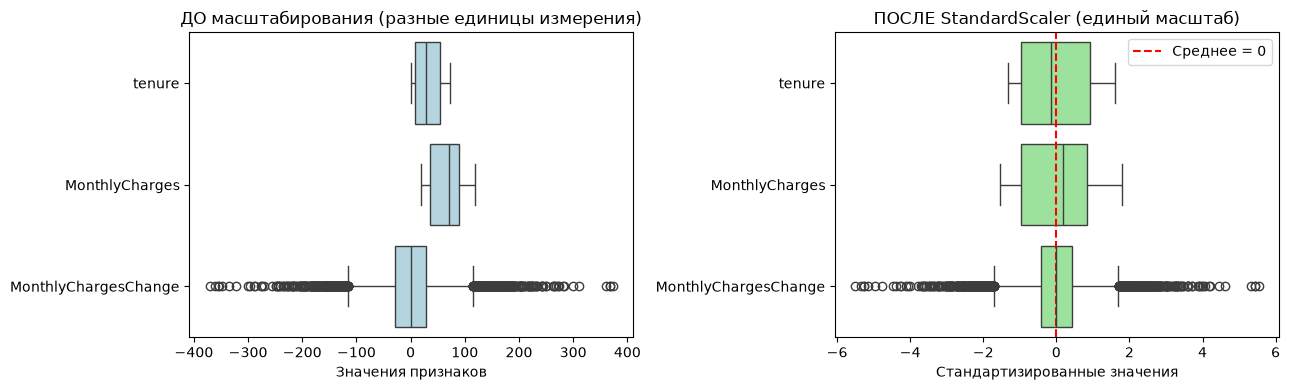

In [64]:
# Наглядно сравним разброс числовых признаков ДО и ПОСЛЕ стандартизации
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=X_train[numeric_features], orient='h', ax=axes[0], color='lightblue')
axes[0].set_title('ДО масштабирования (разные единицы измерения)')
axes[0].set_xlabel('Значения признаков')

sns.boxplot(data=X_train_scaled[numeric_features], orient='h', ax=axes[1], color='lightgreen')
axes[1].axvline(0, color='red', linestyle='--', label='Среднее = 0')
axes[1].set_title('ПОСЛЕ StandardScaler (единый масштаб)')
axes[1].set_xlabel('Стандартизированные значения')
axes[1].legend()

plt.tight_layout()
plt.show()


**Вывод по стандартизации:**
- На левом графике видно, что до масштабирования `MonthlyChargesChange` имел размах в сотни единиц, тогда как `tenure` лежал в пределах `0–72` - сравнивать коэффициенты логистической регрессии на таких "сырых" числах было бы нельзя
- После `StandardScaler` (правый график) все три числовых признака центрированы около `0` и имеют одинаковое стандартное отклонение `1.0`. Данные полностью готовы для обучения моделей


## 11. Построение baseline-моделей

Построим базовые модели (baseline)

Так как классы несбалансированы (73,5% против 26,5%), оценивать модели только по `accuracy` нельзя. Будем ориентироваться на метрики по целевому классу `1` (отток):
- **`Recall` (полнота)** - какую долю реально ушедших абонентов модель смогла обнаружить (главная метрика, чтобы не терять клиентов)
- **`Precision` (точность)** - какая доля клиентов среди тех, кому модель предсказала уход, действительно ушла
- **`F1-score`** - среднее гармоническое `Precision` и `Recall` (общий баланс качества)
- **`ROC-AUC` и `PR-AUC`** - насколько качественно модель оценивает саму вероятность ухода


### 11.1. DummyClassifier

Проверим два варианта `DummyClassifier`:
- `most_frequent` — всегда предсказывает самый частый класс (`0`, "все останутся")
- `stratified` — выдаёт случайные ответы `0` и `1` в той же пропорции, что и в обучающей выборке.


In [65]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

# 1. Dummy (most_frequent)
dummy_most = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_most.fit(X_train_scaled, y_train)
dummy_most_pred = dummy_most.predict(X_test_scaled)
dummy_most_proba = dummy_most.predict_proba(X_test_scaled)[:, 1]

# 2. Dummy (stratified)
dummy_strat = DummyClassifier(strategy='stratified', random_state=42)
dummy_strat.fit(X_train_scaled, y_train)
dummy_strat_pred = dummy_strat.predict(X_test_scaled)
dummy_strat_proba = dummy_strat.predict_proba(X_test_scaled)[:, 1]

print('--- DummyClassifier (most_frequent) ---')
print(classification_report(y_test, dummy_most_pred, zero_division=0))

print('--- DummyClassifier (stratified) ---')
print(classification_report(y_test, dummy_strat_pred, zero_division=0))


--- DummyClassifier (most_frequent) ---
              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409

--- DummyClassifier (stratified) ---
              precision    recall  f1-score   support

           0       0.74      0.74      0.74      1035
           1       0.29      0.29      0.29       374

    accuracy                           0.62      1409
   macro avg       0.52      0.52      0.52      1409
weighted avg       0.62      0.62      0.62      1409



**Вывод по `DummyClassifier`:**
- Модель `most_frequent` получает `accuracy = 0.73`, но при этом у класса `1` (отток) **`recall = 0.00` и `f1 = 0.00`** - модель не нашла ни одного уходящего клиента из 374. Это пример того, почему при дисбалансе классов нельзя смотреть только на `accuracy`.
- Случайная модель `stratified` угадывает уход лишь на уровне случайности (`recall = 0.29`, `precision = 0.29`, `f1 = 0.29`). Любая осмысленная ML-модель должна уверенно превосходить эти цифры.


### 11.2. Логистическая регрессия и роль `class_weight='balanced'`

Теперь обучим **логистическую регрессию** в двух вариантах:
1. Обычную `LogisticRegression` (без учёта дисбаланса классов);
2. `LogisticRegression(class_weight='balanced')` — Параметр `class_weight='balanced'` увеличивает штраф за ошибку на классе `1`, заставляя модель внимательнее ловить уходящих абонентов.


In [66]:
from sklearn.linear_model import LogisticRegression

# 1. Обычная логистическая регрессия
lr_simple = LogisticRegression(random_state=42, max_iter=1000)
lr_simple.fit(X_train_scaled, y_train)
lr_simple_pred = lr_simple.predict(X_test_scaled)
lr_simple_proba = lr_simple.predict_proba(X_test_scaled)[:, 1]

# 2. Логистическая регрессия с балансировкой классов (основной baseline)
lr_balanced = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr_balanced.fit(X_train_scaled, y_train)
lr_balanced_pred = lr_balanced.predict(X_test_scaled)
lr_balanced_proba = lr_balanced.predict_proba(X_test_scaled)[:, 1]

print('--- LogisticRegression (обычная) ---')
print(classification_report(y_test, lr_simple_pred))

print('--- LogisticRegression (class_weight="balanced") ---')
print(classification_report(y_test, lr_balanced_pred))


--- LogisticRegression (обычная) ---
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

--- LogisticRegression (class_weight="balanced") ---
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [67]:
# Посмотрим примеры реальных прогнозов модели lr_balanced на первых 10 клиентах из тестовой выборки
demo_predictions = pd.DataFrame({
    'Факт (y_test)': y_test.values[:10],
    'Прогноз класса': lr_balanced_pred[:10],
    'Вероятность оттока': lr_balanced_proba[:10].round(3),
}, index=X_test.index[:10])

display(demo_predictions)


,Факт (y_test),Прогноз класса,Вероятность оттока
437,0,0,0.099
2280,0,1,0.873
2235,0,0,0.159
4460,0,1,0.670
3761,0,0,0.061
5748,0,1,0.814
3568,0,1,0.707
2976,0,0,0.306
5928,0,0,0.016
1639,1,1,0.644


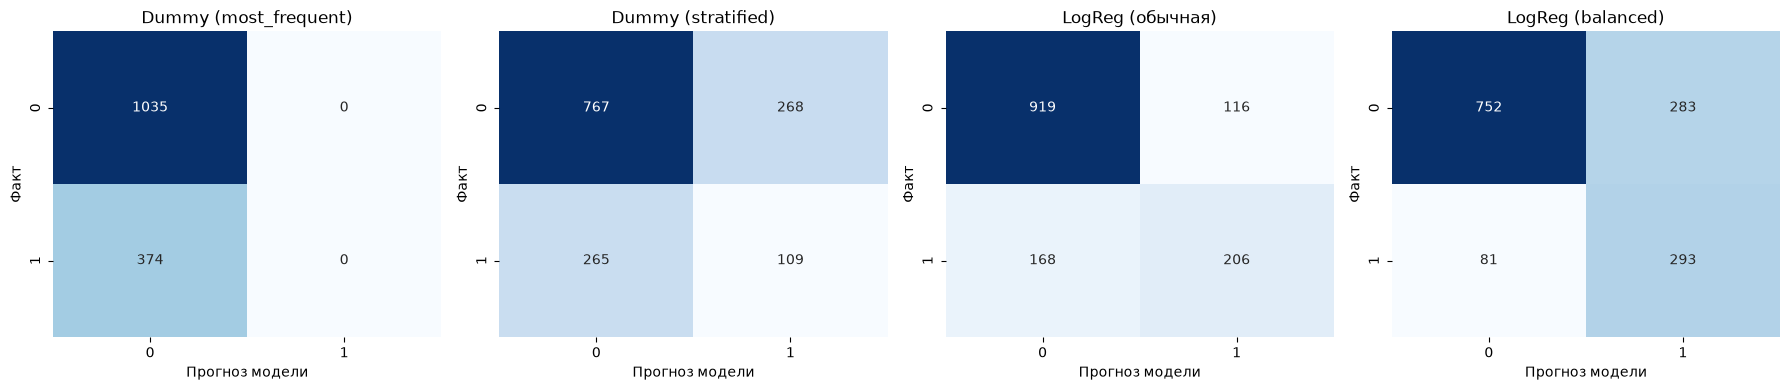

In [68]:
# Визуализируем матрицы ошибок для всех 4 моделей на тестовой выборке (1409 клиентов)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

all_preds = [
    ('Dummy (most_frequent)', dummy_most_pred),
    ('Dummy (stratified)', dummy_strat_pred),
    ('LogReg (обычная)', lr_simple_pred),
    ('LogReg (balanced)', lr_balanced_pred),
]

for ax, (title, preds) in zip(axes, all_preds):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Прогноз модели')
    ax.set_ylabel('Факт')

plt.tight_layout()
plt.show()


**Вывод по матрицам ошибок и `LogisticRegression`:**
- В тестовой выборке **374** реально ушедших клиента (нижняя строка матрицы ошибок).
- Обычная `LogisticRegression` нашла только **205 из 374** ушедших (`Recall = 0.55`), а **169 ушедших клиентов пропустила**.
- `LogisticRegression (class_weight='balanced')` нашла уже **293 из 374** ушедших абонентов (**`Recall = 0.78`**), пропустив лишь 81 человека, но выросло число ложных срабатываний (с 116 до 281, поэтому `Precision = 0.51`), но общий баланс `F1-score` вырос с **0,59 до 0,62**.


### 11.3. Сводная таблица метрик, проверка переобучения и кривые качества (ROC и PR)

Сведём все метрики в единую таблицу, проверим, не переобучилась ли логистическая регрессия (сравним `Train` и `Test`), и построим графики ROC-кривой, PR-кривой и распределения предсказанных вероятностей.


In [69]:
results_df = pd.DataFrame([
    {
        'Модель': 'Dummy (most_frequent)',
        'Accuracy': accuracy_score(y_test, dummy_most_pred),
        'Precision': precision_score(y_test, dummy_most_pred, zero_division=0),
        'Recall': recall_score(y_test, dummy_most_pred, zero_division=0),
        'F1': f1_score(y_test, dummy_most_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, dummy_most_proba),
        'PR-AUC': average_precision_score(y_test, dummy_most_proba),
    },
    {
        'Модель': 'Dummy (stratified)',
        'Accuracy': accuracy_score(y_test, dummy_strat_pred),
        'Precision': precision_score(y_test, dummy_strat_pred, zero_division=0),
        'Recall': recall_score(y_test, dummy_strat_pred, zero_division=0),
        'F1': f1_score(y_test, dummy_strat_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, dummy_strat_proba),
        'PR-AUC': average_precision_score(y_test, dummy_strat_proba),
    },
    {
        'Модель': 'LogReg (обычная)',
        'Accuracy': accuracy_score(y_test, lr_simple_pred),
        'Precision': precision_score(y_test, lr_simple_pred),
        'Recall': recall_score(y_test, lr_simple_pred),
        'F1': f1_score(y_test, lr_simple_pred),
        'ROC-AUC': roc_auc_score(y_test, lr_simple_proba),
        'PR-AUC': average_precision_score(y_test, lr_simple_proba),
    },
    {
        'Модель': 'LogReg (balanced)',
        'Accuracy': accuracy_score(y_test, lr_balanced_pred),
        'Precision': precision_score(y_test, lr_balanced_pred),
        'Recall': recall_score(y_test, lr_balanced_pred),
        'F1': f1_score(y_test, lr_balanced_pred),
        'ROC-AUC': roc_auc_score(y_test, lr_balanced_proba),
        'PR-AUC': average_precision_score(y_test, lr_balanced_proba),
    },
]).round(3)

print('Сравнение всех baseline-моделей на тестовой выборке:')
display(results_df)

# Проверим, нет ли переобучения у основной модели LogReg (balanced): сравним метрики на Train и Test
train_pred_bal = lr_balanced.predict(X_train_scaled)
train_proba_bal = lr_balanced.predict_proba(X_train_scaled)[:, 1]

overfit_check = pd.DataFrame([
    {
        'Выборка': 'Train (обучающая)',
        'Accuracy': accuracy_score(y_train, train_pred_bal),
        'Precision': precision_score(y_train, train_pred_bal),
        'Recall': recall_score(y_train, train_pred_bal),
        'F1': f1_score(y_train, train_pred_bal),
        'ROC-AUC': roc_auc_score(y_train, train_proba_bal),
    },
    {
        'Выборка': 'Test (тестовая)',
        'Accuracy': accuracy_score(y_test, lr_balanced_pred),
        'Precision': precision_score(y_test, lr_balanced_pred),
        'Recall': recall_score(y_test, lr_balanced_pred),
        'F1': f1_score(y_test, lr_balanced_pred),
        'ROC-AUC': roc_auc_score(y_test, lr_balanced_proba),
    },
]).round(3)

print('Проверка на переобучение для LogReg (balanced):')
display(overfit_check)


Сравнение всех baseline-моделей на тестовой выборке:


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Dummy (most_frequent),0.735,0.000,0.000,0.000,0.500,0.265
1,Dummy (stratified),0.622,0.289,0.291,0.290,0.516,0.272
2,LogReg (обычная),0.798,0.640,0.551,0.592,0.839,0.630
3,LogReg (balanced),0.742,0.509,0.783,0.617,0.839,0.629


Проверка на переобучение для LogReg (balanced):


,Выборка,Accuracy,Precision,Recall,F1,ROC-AUC
0,Train (обучающая),0.752,0.521,0.799,0.631,0.848
1,Test (тестовая),0.742,0.509,0.783,0.617,0.839


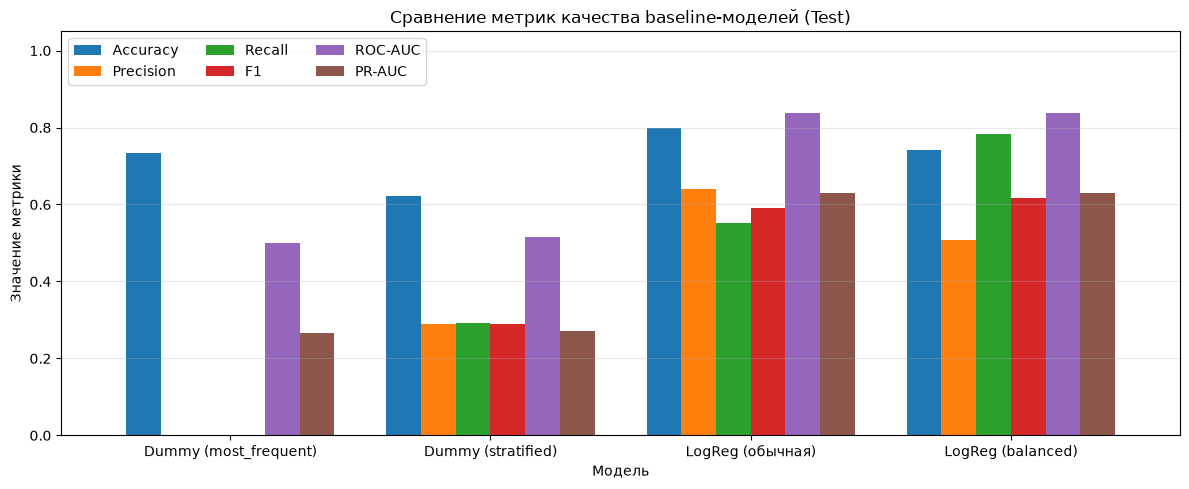

In [70]:
# Наглядное сравнение метрик всех четырёх моделей на столбчатой диаграмме
ax = results_df.set_index('Модель')[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']].plot(
    kind='bar', figsize=(12, 5), width=0.8
)
ax.set_title('Сравнение метрик качества baseline-моделей (Test)')
ax.set_ylabel('Значение метрики')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)
plt.legend(loc='upper left', ncol=3)
plt.tight_layout()
plt.show()


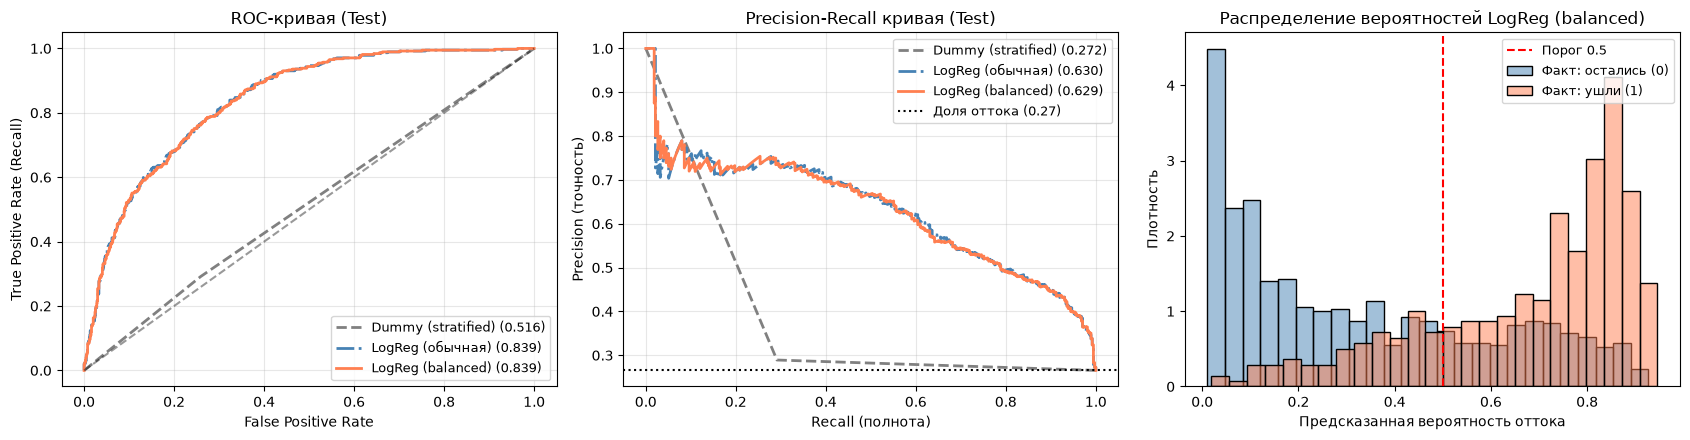

In [71]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. ROC-кривая
for name, proba, color, ls in [
    ('Dummy (stratified)', dummy_strat_proba, 'gray', '--'),
    ('LogReg (обычная)', lr_simple_proba, 'steelblue', '-.'),
    ('LogReg (balanced)', lr_balanced_proba, 'coral', '-'),
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, color=color, linestyle=ls, linewidth=2, label=f'{name} ({auc_val:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_title('ROC-кривая (Test)')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# 2. Precision-Recall кривая
for name, proba, color, ls in [
    ('Dummy (stratified)', dummy_strat_proba, 'gray', '--'),
    ('LogReg (обычная)', lr_simple_proba, 'steelblue', '-.'),
    ('LogReg (balanced)', lr_balanced_proba, 'coral', '-'),
]:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap_val = average_precision_score(y_test, proba)
    axes[1].plot(rec, prec, color=color, linestyle=ls, linewidth=2, label=f'{name} ({ap_val:.3f})')

axes[1].axhline(y_test.mean(), color='black', linestyle=':', label=f'Доля оттока ({y_test.mean():.2f})')
axes[1].set_title('Precision-Recall кривая (Test)')
axes[1].set_xlabel('Recall (полнота)')
axes[1].set_ylabel('Precision (точность)')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

# 3. Как распределены предсказанные вероятности у оставшихся и ушедших клиентов
sns.histplot(lr_balanced_proba[y_test == 0], bins=25, color='steelblue', alpha=0.5,
             stat='density', label='Факт: остались (0)', ax=axes[2])
sns.histplot(lr_balanced_proba[y_test == 1], bins=25, color='coral', alpha=0.5,
             stat='density', label='Факт: ушли (1)', ax=axes[2])
axes[2].axvline(0.5, color='red', linestyle='--', label='Порог 0.5')
axes[2].set_title('Распределение вероятностей LogReg (balanced)')
axes[2].set_xlabel('Предсказанная вероятность оттока')
axes[2].set_ylabel('Плотность')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()


**Вывод по метрикам и графикам вероятностей:**
- **Переобучения нет:** у `LogReg (balanced)` метрики на `Train` (`F1 = 0.631`, `ROC-AUC = 0.848`) и на `Test` (`F1 = 0.617`, `ROC-AUC = 0.839`) практически одинаковые - модель хорошо обобщает закономерности на новых клиентов.
- **Качество ранжирования высокое:** `ROC-AUC = 0.839` и `PR-AUC = 0.629` (более чем в 2 раза выше случайного уровня `0.265`). При этом ROC- и PR-кривые у обычной и взвешенной регрессии почти совпадают - то есть вероятности они ранжируют одинаково хорошо, а `class_weight='balanced'` сдвигает саму границу принятия решения в пользу обнаружения уходящих клиентов.
- На правом графике хорошо видно разделение двух групп: у большинства оставшихся клиентов (синий цвет) предсказанная вероятность ухода сосредоточена слева (около `0.05-0.30`), а у реально ушедших (оранжевый цвет) - справа (около `0.65-0.85`).


### 11.4. Зависимость метрик от порога вероятности

По умолчанию граница отнесения к классу `1` равна `0.5`. Проверим (как делалось на Вебинаре 4), как меняются `Recall`, `Precision` и `F1-score` у `LogReg (balanced)`, если менять порог вероятности от `0.1` до `0.9` с шагом `0.05`


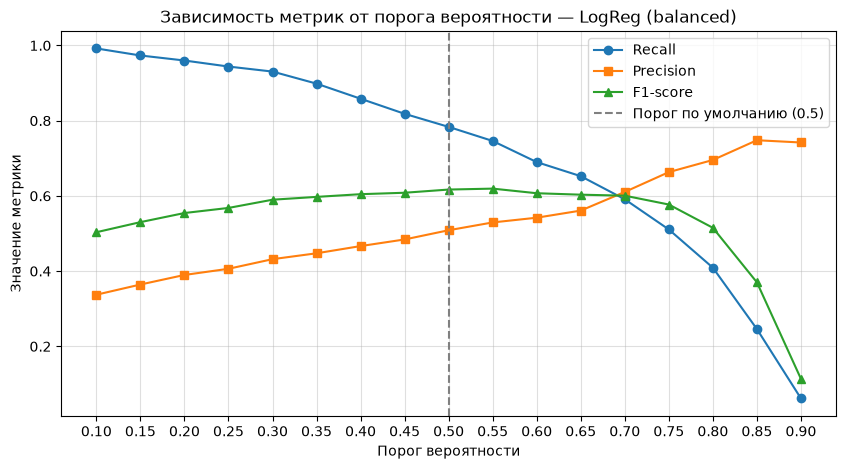

In [72]:
recall_scores = []
precision_scores = []
f1_scores = []

thresholds = np.arange(0.1, 0.95, 0.05)

for threshold in thresholds:
    y_pred_thr = (lr_balanced_proba > threshold).astype(int)
    recall_scores.append(recall_score(y_test, y_pred_thr, zero_division=0))
    precision_scores.append(precision_score(y_test, y_pred_thr, zero_division=0))
    f1_scores.append(f1_score(y_test, y_pred_thr, zero_division=0))

plt.figure(figsize=(10, 5))
plt.plot(thresholds, recall_scores, marker='o', label='Recall')
plt.plot(thresholds, precision_scores, marker='s', label='Precision')
plt.plot(thresholds, f1_scores, marker='^', label='F1-score')

plt.axvline(0.5, color='gray', linestyle='--', label='Порог по умолчанию (0.5)')
plt.title('Зависимость метрик от порога вероятности — LogReg (balanced)')
plt.xlabel('Порог вероятности')
plt.ylabel('Значение метрики')
plt.xticks(np.round(thresholds, 2))
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()


**Вывод по порогу вероятности:**
- При увеличении порога `Precision` растёт (меньше ложных), но `Recall` падает (пропускаем больше уходящих клиентов)
- Максимальное значение `F1-score` (~`0.62`) достигается как раз в районе порога **`0.50–0.55`**, а пересечение кривых `Precision` и `Recall` находится около порога `0.65` Значит, стандартный порог `0.5` для сбалансированной регрессии уже даёт оптимальный `F1` при высоком охвате оттока (`Recall = 0.78`)


### 11.5. Интерпретация коэффициентов модели (ключевые факторы риска ухода)

Так как все признаки приведены к сопоставимому масштабу, посмотрим на веса `lr_balanced.coef_`, которые выучила модель:
- **положительный вес (`> 0`)** — признак **повышает риск оттока**
- **отрицательный вес (`< 0`)** — признак **снижает риск оттока** (удерживает абонента)


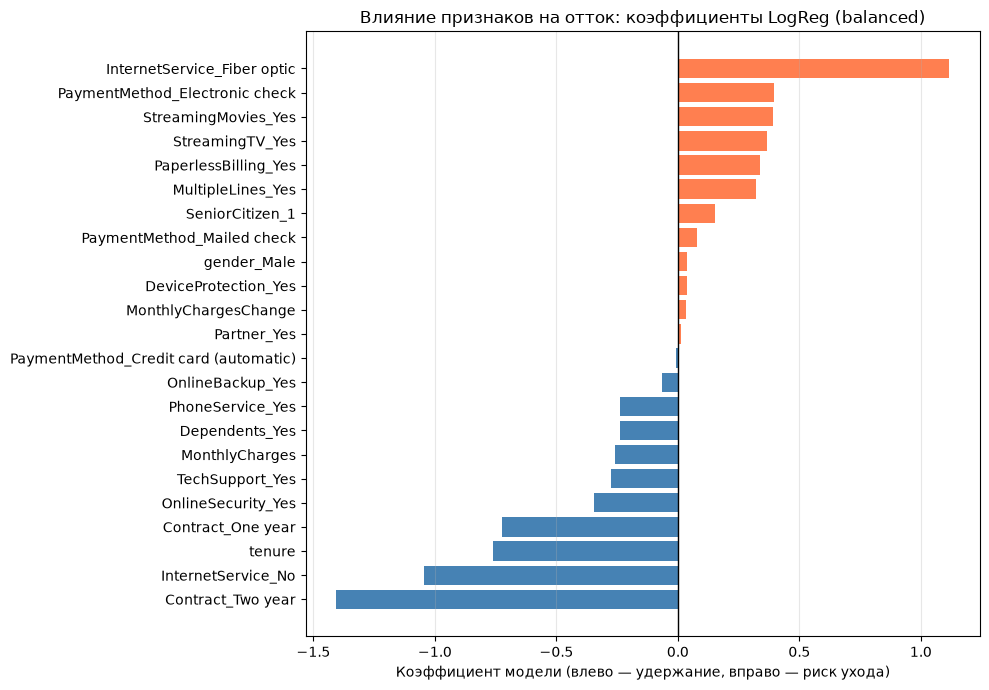

Топ-5 факторов РИСКА ухода (максимальные положительные коэффициенты):


,Признак,Коэффициент
9,InternetService_Fiber optic,1.117
21,PaymentMethod_Electronic check,0.397
16,StreamingMovies_Yes,0.391
15,StreamingTV_Yes,0.369
19,PaperlessBilling_Yes,0.337


Топ-5 факторов УДЕРЖАНИЯ (максимальные по модулю отрицательные коэффициенты):


,Признак,Коэффициент
18,Contract_Two year,-1.406
10,InternetService_No,-1.045
0,tenure,-0.760
17,Contract_One year,-0.723
11,OnlineSecurity_Yes,-0.343


In [73]:
coef_df = pd.DataFrame({
    'Признак': X_train_scaled.columns,
    'Коэффициент': lr_balanced.coef_[0]
}).sort_values('Коэффициент', ascending=True)

plt.figure(figsize=(10, 7))
colors = ['steelblue' if c < 0 else 'coral' for c in coef_df['Коэффициент']]
plt.barh(coef_df['Признак'], coef_df['Коэффициент'], color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Влияние признаков на отток: коэффициенты LogReg (balanced)')
plt.xlabel('Коэффициент модели (влево — удержание, вправо — риск ухода)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print('Топ-5 факторов РИСКА ухода (максимальные положительные коэффициенты):')
display(coef_df.sort_values('Коэффициент', ascending=False).head(5).round(3))

print('Топ-5 факторов УДЕРЖАНИЯ (максимальные по модулю отрицательные коэффициенты):')
display(coef_df.sort_values('Коэффициент', ascending=True).head(5).round(3))


**Вывод по факторам оттока:**
- **Главные факторы риска ухода:** подключённый оптоволоконный интернет (`InternetService_Fiber optic`, коэфф. `+1.12`), оплата электронным чеком (`PaymentMethod_Electronic check`, `+0.40`), подписки `StreamingMovies` (`+0.39`) и `StreamingTV` (`+0.37`), а также безбумажный счёт `PaperlessBilling_Yes` (`+0.34`)
- **Главные факторы удержания:** долгосрочные контракты на два года (`Contract_Two year`, `-1.41`) и на один год (`Contract_One year`, `-0.72`) по сравнению с помесячной оплатой, отсутствие интернет-услуг (`InternetService_No`, `-1.05`), большой срок жизни клиента `tenure` (`-0.76`), а также подключённые защитные сервисы `OnlineSecurity_Yes` (`-0.34`) и `TechSupport_Yes` (`-0.27`)


---

## 12. Общие итоги по разделению выборки и построению baseline

1. **Данные подготовлены и разделены (`train_test_split`, `stratify=y`):**
   - Отобраны 23 признака без пропусков и дублирующих категорий, выборка разбита в пропорции 80/20 (`5 634` в `Train` и `1 409` в `Test`) с точным сохранением доли оттока **26,54%**
   - Числовые признаки стандартизированы через `StandardScaler` строго по обучающей выборке
2. **Построен и проверен baseline:**
   - Модели `DummyClassifier` (`F1 = 0.00` для `most_frequent` и `F1 = 0.29` для `stratified`) показали непригодность тк `Accuracy` в отрыве от остальных метрик.
   - В качестве основного ориентира зафиксирована **`LogisticRegression (class_weight='balanced')`**: на тестовой выборке она показывает **`Recall = 0.783`** , **`Precision = 0.509`**, **`F1 = 0.617`**, **`ROC-AUC = 0.839`**, **`PR-AUC = 0.629`** и не имеет переобучения

